<a href="https://colab.research.google.com/github/kmreardon-qt/MPM_200_Reardon/blob/main/notebooks/KReardon_assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [6]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [7]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Reardon!", by = "yoda")


 _________________________________________ 
< Welcome to Hummingbird HQ, Dr. Reardon! >
 ----------------------------------------- 
                \
                 \

                   ____
                _.' :  `._
            .-.'`.  ;   .'`.-.
   __      / : ___\ ;  /___ ; \      __
  ,'_ ""--.:__;".-.";: :".-.":__;.--"" _`,
  :' `.t""--.. '<@.`;_  ',@>` ..--""j.' `;
       `:-.._J '-.-'L__ `-- ' L_..-;'
          "-.__ ;  .-"  "-.  : __.-"
             L ' /.------.\ ' J
             "-.   "--"   .-"
             __.l"-:_JL_;-";.__
         .-j/'.;  ;""""  / .'\"-.
         .' /:`. "-.:     .-" .';  `.
      .-"  / ;  "-. "-..-" .-"  :    "-.
  .+"-.  : :      "-.__.-"      ;-._   \
  ; \  `.; ;                    : : "+. ;
  :  ;   ; ;                    : ;  : \:
  ;  :   ; :                    ;:   ;  :
  : \  ;  :  ;                  : ;  /  ::
  ;  ; :   ; :                  ;   :   ;:
  :  :  ;  :  ;                : :  ;  : ;
  ;\    :   ; :                ; ;     ; ;


In [8]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [9]:
# url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("/content/sample_data/Hummingbird_data.csv")
colnames(data)


[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `_5,500___`.
Now find how many rows and columns `data` has.

In [10]:
dim(data)      # rows, columns
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [11]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** Admitted is stored as a character not a date. The only integer in the data is Brought_in_after

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [12]:
set.seed(0127)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [13]:
dim(model_data)

[1] 5000   12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:**

The continuous column is Brought_in_after and is an integer. ID is useful for data organization and tracing back an outlier, but less useful for actual analysis.

In [14]:
str(model_data)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "7/3/2002" "7/25/2010" "7/9/2015" "5/15/1997" ...
 $ Disposition_binary: chr  "Released" "Died" "Released" "Released" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "No" "Yes" ...
 $ Species_e         : chr  "Non-selasphorus" "Selasphorus" "Selasphorus" "Non-selasphorus" ...
 $ Sex_e             : chr  "unknown" "Female-like " "unknown" "unknown" ...
 $ Age_e             : chr  "Nestling" "adult-like" "Nestling" "Nestling" ...
 $ Brought_in_after  : int  0 0 0 0 1 1 3 7 0 2 ...
 $ season            : chr  "Summer" "Summer" "Summer" "Spring" ...
 $ r                 : chr  "found on the ground" "found inside" "nest-related" "nest-related" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "2301_ANHU" "4035_ALHU" "5414_ALHU" "1235_ANHU" ...


**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [15]:
write.csv(model_data, "outputs/Hummingbird_data_KReardon.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [16]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4133
Santa Barbara,69
malibu,798


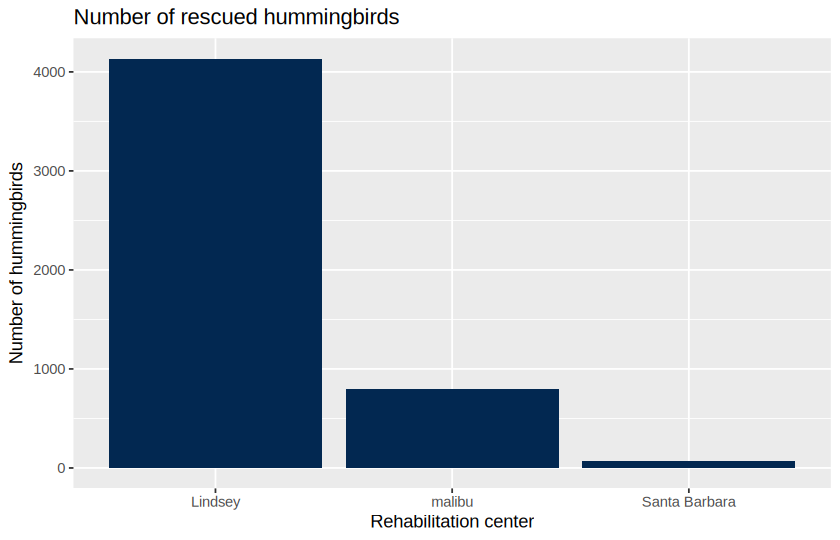

In [17]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [18]:
ggsave("outputs/rehab_counts_KReardon.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**

rehab, aes(x = Place, y = count)) +
- Pulls the data from the rehab table and lets r know we want to make a graph with the x axis variable Place and the y axis variable count.

geom_col(fill = "#022851") +
- lets r know we want to make a bar chart and fill the bars with the color Aggie Blue.
  
xlab("Rehabilitation center") +
- labels the x axis of our chart

ylab("Number of hummingbirds") +
- labels the y axis of our chart

labs(title = "Number of rescued hummingbirds")
- allows us to title the chart

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:**

Raw counts are not enough to compare the outcomes between the three centers because we don't know if there is a larger hummingbird population in Lindsey or that all admitted birds died.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [19]:
df_season <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_season

season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,368
Fall,Released,57
Spring,Died,1324
Spring,Released,940
Summer,Died,942
Summer,Released,604
Winter,Died,572
Winter,Released,193


In [20]:
df_age <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_age

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,418
Nestling,Released,766
adult-like,Died,2788
adult-like,Released,1028


In [21]:
df_F_Aid <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_F_Aid

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2091
No,Released,1204
Yes,Died,1115
Yes,Released,590


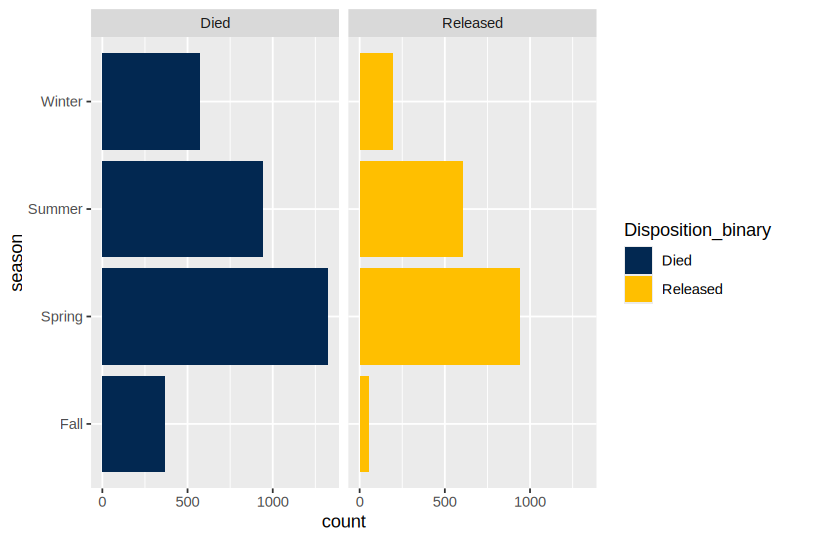

In [22]:
ggplot(df_season, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

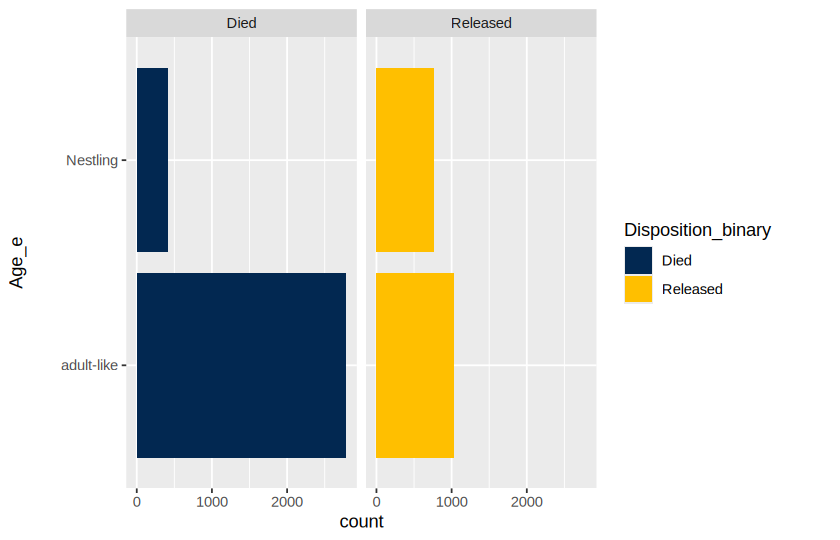

In [23]:
ggplot(df_age, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

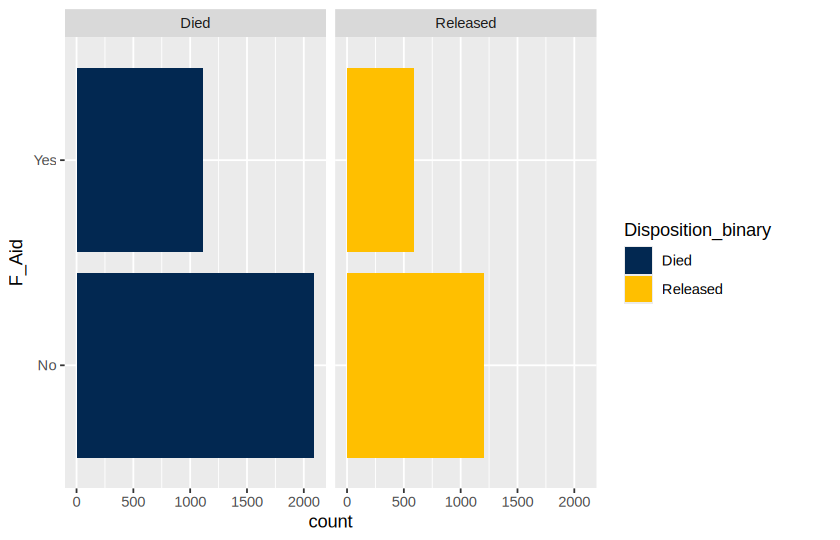

In [24]:
ggplot(df_F_Aid, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:**

Based on these plots, it appears that more birds were adults that were taken in and didn't survive, there is a possible seasonality component, and that if they recieve first aid or not doesn't seem to increase their odds of survival. We could do p-value testing to see if there is true association, because we don't want to just infer based on these plots.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

In [25]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = (count / sum(count)))
proportions


Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2665,0.6448101
Lindsey,Released,1468,0.3551899
Santa Barbara,Died,40,0.5797101
Santa Barbara,Released,29,0.4202899
malibu,Died,501,0.6278195
malibu,Released,297,0.3721805


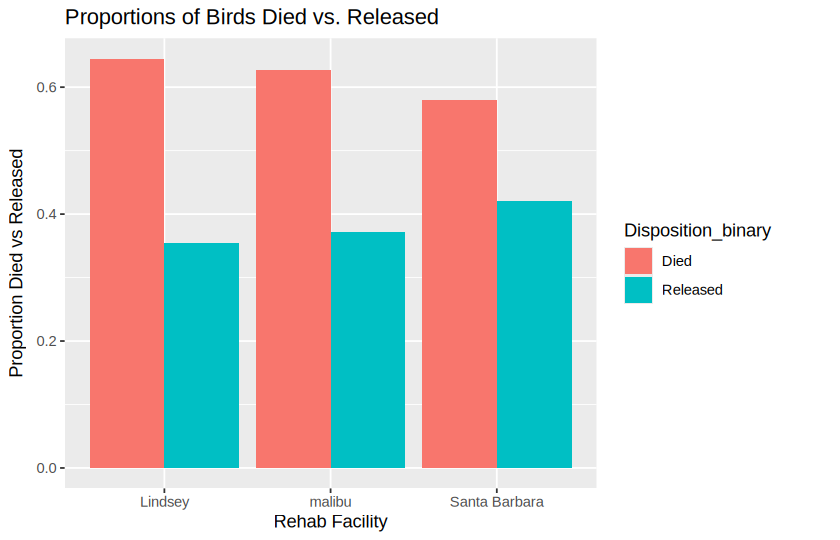

In [26]:
ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehab Facility") +
  ylab("Proportion Died vs Released") +
  labs(title = "Proportions of Birds Died vs. Released")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4123                0
  Selasphorus                        0              877

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-selasphorus,Died,2647,0.6420082
Non-selasphorus,Released,1476,0.3579918
Selasphorus,Died,559,0.6374002
Selasphorus,Released,318,0.3625998


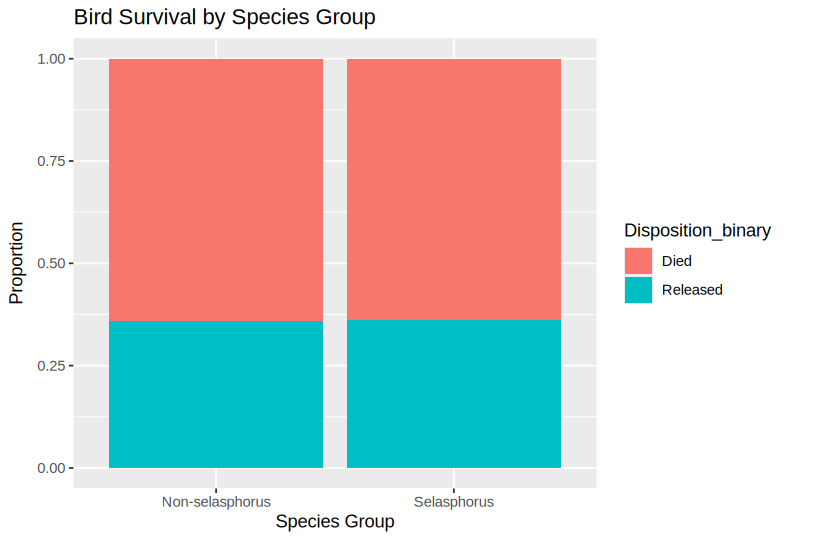

In [27]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count= n_distinct(ID), .groups="drop") %>%
  group_by(Species_group) %>%
  mutate(proportion= count/ sum(count))

species_distribution #show table


ggplot(species_distribution, aes(x = Species_group, y = proportion, fill = Disposition_binary )) +
  geom_col() +
  xlab("Species Group") +
  ylab("Proportion") +
  labs(title = "Bird Survival by Species Group")


✍️ **Your answer:**
The survival porportions differed minimally in this case. It appears species group did not affect how many died or were released.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [28]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:**

The format function allows us to transform/format things like date into an easier way to read. Running it "%d/%m/%Y" returns NA because it is not recorded that way in the original data.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `_Late Spring/ Early Summer_` Why? Due to migration and nesting.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [29]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count= n())

admissions_by_month

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count= n())

admissions_by_year

table(model_data$season)

Admitted_month,count
<chr>,<int>
1991-01,13
1991-02,3
1991-03,19
1991-04,29
1991-05,15
1991-06,24
1991-07,12
1991-08,9
1991-09,7


Admitted_year,count
<chr>,<int>
1991,140
1992,127
1993,135
1994,121
1995,140
1996,149
1997,129
1998,141
1999,156



  Fall Spring Summer Winter 
   425   2264   1546    765 

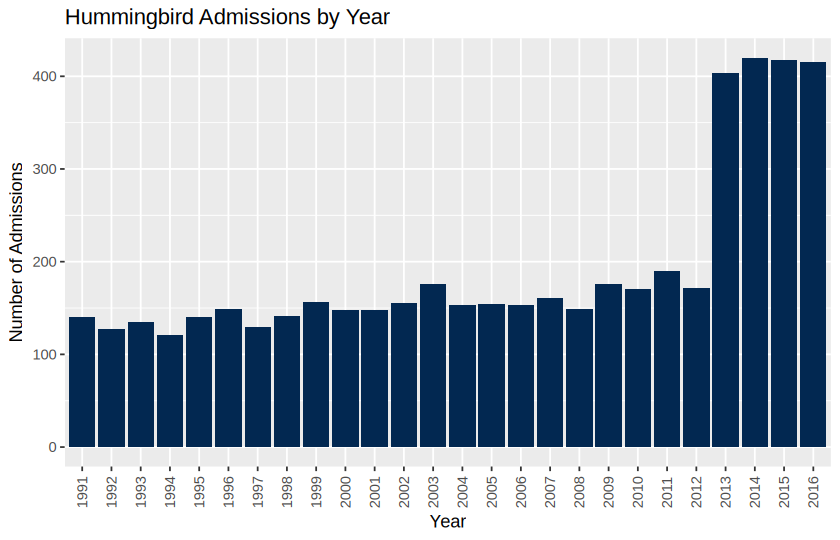

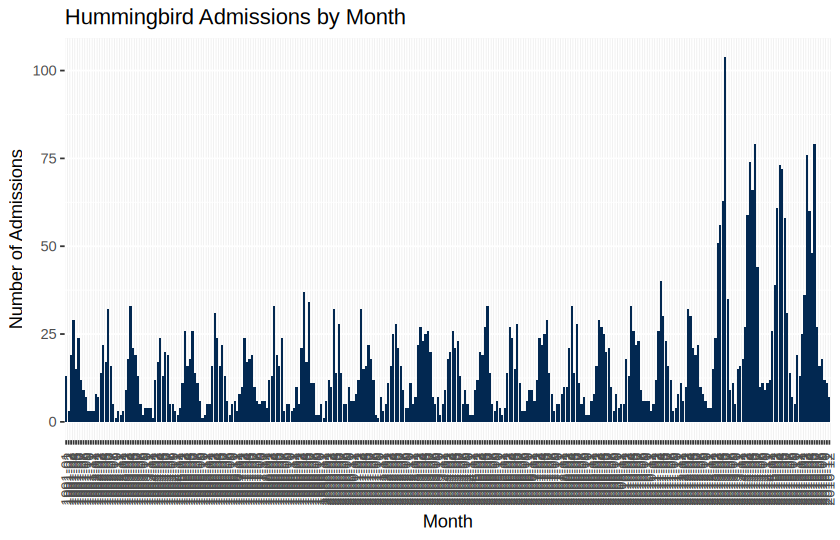

In [30]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [31]:
# your investigation here
model_data %>%
  count(Admitted_year = format(Admitted_date, "%Y"), Place)

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,140
1992,Lindsey,127
1993,Lindsey,135
1994,Lindsey,121
1995,Lindsey,140
1996,Lindsey,149
1997,Lindsey,129
1998,Lindsey,141
1999,Lindsey,156


✍️ **Your answer:**
Two more rehabilitation centers were created past 2013 allowing for more hummingbird intakes and care.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [32]:
# your detective work here
summary(data$Brought_in_after)
unique(data$Sex_e)
unique(data$Place)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -365.000     0.000     0.000     3.058     1.000 16588.000 

[1] "Female-like " "unknown"      "Male"

[1] "Lindsey"       "malibu"        "Santa Barbara"

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**
One thing about this data set that suprised me is how far back the data collection went. One R error I hit was in question 13, I initially tried to use prop.table() which did not work because it was a dataframe with numeric and categorical variables. I fixed it by using the group_by() and mutate () functions instead.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [33]:
beep_colab("smb_stage_clear")   # mission complete 🍄

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_month and Species_group.
ℹ Output is grouped by Admitted_month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_month, Species_group))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


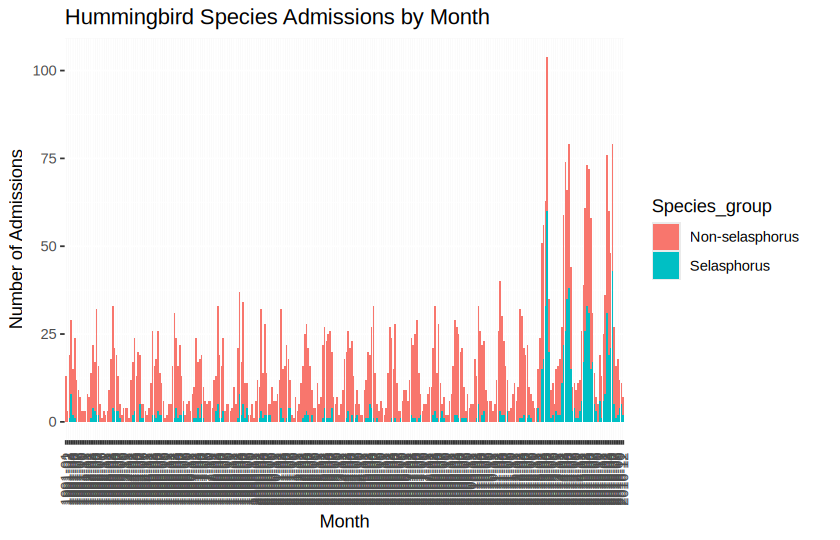

In [34]:
# Github assignment
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n())

ggplot(admissions_by_month, aes(x = Admitted_month, y = count, fill= Species_group)) +
  geom_col() +
  xlab("Month") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Species Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))


# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [43]:
model_data$Disposition_binary<- as.factor(model_data$Disposition_binary)


In [44]:
fullmodel  = glm(Disposition_binary~ r + Green_Orange + season+F_Aid+Species_e, data = model_data, family= binomial(link = logit))
fullmodel


Call:  glm(formula = Disposition_binary ~ r + Green_Orange + season + 
    F_Aid + Species_e, family = binomial(link = logit), data = model_data)

Coefficients:
                 (Intercept)                 rfound inside  
                   -1.956349                      0.102323  
        rfound on the ground                 rnest-related  
                    0.101631                      0.665785  
  rsuspect torpor-like state                      runknown  
                   -1.181836                      0.389275  
                 rwindow hit  Green_OrangeSelasphorus spp.  
                    0.004701                      0.175924  
                seasonSpring                  seasonSummer  
                    1.103012                      1.024221  
                seasonWinter                      F_AidYes  
                    0.528042                     -0.117076  
               Species_eBCHU      Species_eNon-selasphorus  
                    0.762138                 

2. use following command with full model to do stepwise model selection

In [45]:
backward_model = step(fullmodel,k=2,direction = "backward",test="Chisq")

Start:  AIC=5932.34
Disposition_binary ~ r + Green_Orange + season + F_Aid + Species_e


Step:  AIC=5932.34
Disposition_binary ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5904.3 5932.3                      
- F_Aid      1   5907.4 5933.4   3.039   0.08129 .  
- r          6   5966.9 5982.9  62.570  1.35e-11 ***
- season     3   5991.4 6013.4  87.114 < 2.2e-16 ***
- Species_e  3   6109.7 6131.7 205.388 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [46]:
forward_model = step(fullmodel,k=2,direction = ,test="Chisq")

Start:  AIC=5932.34
Disposition_binary ~ r + Green_Orange + season + F_Aid + Species_e


Step:  AIC=5932.34
Disposition_binary ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5904.3 5932.3                      
- F_Aid      1   5907.4 5933.4   3.039   0.08129 .  
- r          6   5966.9 5982.9  62.570  1.35e-11 ***
- season     3   5991.4 6013.4  87.114 < 2.2e-16 ***
- Species_e  3   6109.7 6131.7 205.388 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [48]:
names(backward_model)
length(fullmodel)

[1] "coefficients"      "residuals"         "fitted.values"    
 [4] "effects"           "R"                 "rank"             
 [7] "qr"                "family"            "linear.predictors"
[10] "deviance"          "aic"               "null.deviance"    
[13] "iter"              "weights"           "prior.weights"    
[16] "df.residual"       "df.null"           "y"                
[19] "converged"         "boundary"          "model"            
[22] "call"              "formula"           "terms"            
[25] "data"              "offset"            "control"          
[28] "method"            "contrasts"         "xlevels"          
[31] "anova"

[1] 30

## Q1: How many model properties are available? ##
31

explore individual attributes of the fitted model and read about it in the R documentation

In [50]:
install.packages("sjPlot")
library(sjPlot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘rbibutils’, ‘Rdpack’, ‘reformulas’, ‘effectsize’, ‘bayestestR’, ‘datawizard’, ‘ggeffects’, ‘insight’, ‘parameters’, ‘performance’, ‘sjlabelled’, ‘sjmisc’, ‘sjstats’



Attaching package: ‘sjPlot’


The following object is masked from ‘package:ggplot2’:

    set_theme




In [51]:
tab_model(backward_model)

In [53]:
table_html <- tab_model(backward_model)
IRdisplay::display_html(as.character(table_html))

Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.11 
 0.74 – 1.64 
 0.613 
 
 
 r [found on the ground] 
 1.11 
 0.91 – 1.36 
 0.324 
 
 
 r [nest-related] 
 1.95 
 1.51 – 2.52 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.31 
 0.14 – 0.59 
 0.001 
 
 
 r [unknown] 
 1.48 
 1.17 – 1.87 
 0.001 
 
 
 r [window hit] 
 1.00 
 0.76 – 1.33 
 0.974 
 
 
 season [Spring] 
 3.01 
 2.25 – 4.10 
 <0.001 
 
 
 season [Summer] 
 2.78 
 2.07 – 3.81 
 <0.001 
 
 
 season [Winter] 
 1.70 
 1.23 – 2.37 
 0.002 
 
 
 F Aid [Yes] 
 0.89 
 0.78 – 1.01 
 0.082 
 
 
 Species e [BCHU] 
 2.14 
 1.06 – 4.29 
 0.031 
 
 
 Species e [Non-selasphorus] 
 3.47 
 2.91 – 4.13 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.41 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.123 
 

 
 
 
 

 
 
 
 
   
 Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.11 
 0.74 – 1.64 
 0.613 
 
 
 r [found on the ground] 
 1.11 
 0.91 – 1.36 
 0.324 
 
 
 r [nest-related] 
 1.95 
 1.51 – 2.52 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.31 
 0.14 – 0.59 
 0.001 
 
 
 r [unknown] 
 1.48 
 1.17 – 1.87 
 0.001 
 
 
 r [window hit] 
 1.00 
 0.76 – 1.33 
 0.974 
 
 
 season [Spring] 
 3.01 
 2.25 – 4.10 
 <0.001 
 
 
 season [Summer] 
 2.78 
 2.07 – 3.81 
 <0.001 
 
 
 season [Winter] 
 1.70 
 1.23 – 2.37 
 0.002 
 
 
 F Aid [Yes] 
 0.89 
 0.78 – 1.01 
 0.082 
 
 
 Species e [BCHU] 
 2.14 
 1.06 – 4.29 
 0.031 
 
 
 Species e [Non-selasphorus] 
 3.47 
 2.91 – 4.13 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.41 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.123 
 

 

 
 
   
 Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.11 
 0.74 – 1.64 
 0.613 
 
 
 r [found on the ground] 
 1.11 
 0.91 – 1.36 
 0.324 
 
 
 r [nest-related] 
 1.95 
 1.51 – 2.52 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.31 
 0.14 – 0.59 
 0.001 
 
 
 r [unknown] 
 1.48 
 1.17 – 1.87 
 0.001 
 
 
 r [window hit] 
 1.00 
 0.76 – 1.33 
 0.974 
 
 
 season [Spring] 
 3.01 
 2.25 – 4.10 
 <0.001 
 
 
 season [Summer] 
 2.78 
 2.07 – 3.81 
 <0.001 
 
 
 season [Winter] 
 1.70 
 1.23 – 2.37 
 0.002 
 
 
 F Aid [Yes] 
 0.89 
 0.78 – 1.01 
 0.082 
 
 
 Species e [BCHU] 
 2.14 
 1.06 – 4.29 
 0.031 
 
 
 Species e [Non-selasphorus] 
 3.47 
 2.91 – 4.13 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.41 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.123 
 

 
NULLTRUE

Q2:Nonsephalorous had the highest OR

Q3: Yes the calculated odds ratios match the values provided by sjPlot.